In [2]:
# ============================================================
# 📘 STUDENT PLACEMENT PREDICTION USING MACHINE LEARNING
# ============================================================

# 1️⃣ Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [3]:
# 2️⃣ Load the Dataset
# ============================================================
df = pd.read_csv("Placement_Data_Full_Class.csv")
print("Dataset loaded successfully!\n")
print(df.head())

Dataset loaded successfully!

   sl_no gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p  \
0      1      M  67.00   Others  91.00   Others  Commerce     58.00   
1      2      M  79.33  Central  78.33   Others   Science     77.48   
2      3      M  65.00  Central  68.00  Central      Arts     64.00   
3      4      M  56.00  Central  52.00  Central   Science     52.00   
4      5      M  85.80  Central  73.60  Central  Commerce     73.30   

    degree_t workex  etest_p specialisation  mba_p      status    salary  
0   Sci&Tech     No     55.0         Mkt&HR  58.80      Placed  270000.0  
1   Sci&Tech    Yes     86.5        Mkt&Fin  66.28      Placed  200000.0  
2  Comm&Mgmt     No     75.0        Mkt&Fin  57.80      Placed  250000.0  
3   Sci&Tech     No     66.0         Mkt&HR  59.43  Not Placed       NaN  
4  Comm&Mgmt     No     96.8        Mkt&Fin  55.50      Placed  425000.0  


In [4]:
# 3️⃣ Basic Information about Dataset
# ============================================================
print("\nShape of dataset:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nData types:\n", df.dtypes)



Shape of dataset: (215, 15)

Missing values:
 sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

Data types:
 sl_no               int64
gender             object
ssc_p             float64
ssc_b              object
hsc_p             float64
hsc_b              object
hsc_s              object
degree_p          float64
degree_t           object
workex             object
etest_p           float64
specialisation     object
mba_p             float64
status             object
salary            float64
dtype: object


C:\Users\User\AppData\Local\Temp\ipykernel_24120\1009228153.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status', data=df, palette='coolwarm')


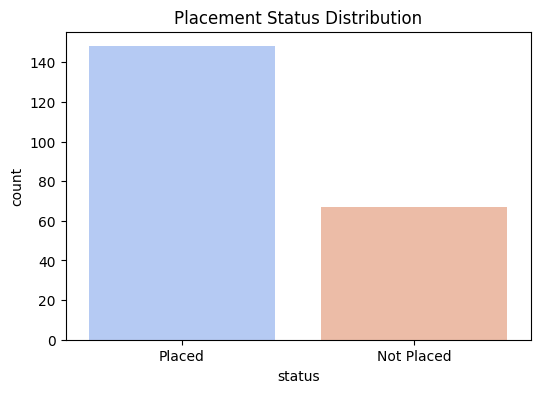

C:\Users\User\AppData\Local\Temp\ipykernel_24120\1009228153.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='status', y='cgpa', data=df, palette='Set2')


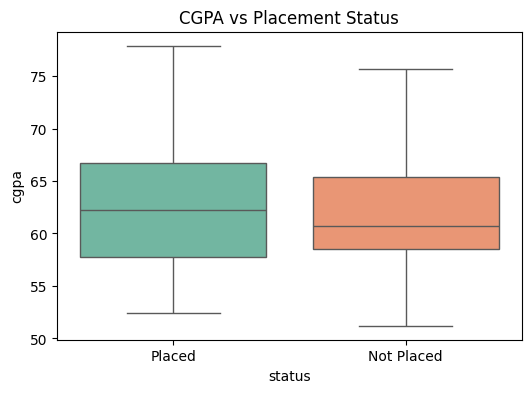

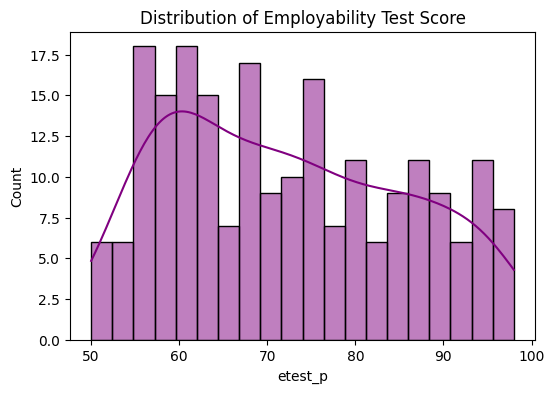

In [6]:
# 4️⃣ Exploratory Data Analysis (EDA)
# ============================================================
plt.figure(figsize=(6,4))
sns.countplot(x='status', data=df, palette='coolwarm')
plt.title("Placement Status Distribution")
plt.show()

# Rename column if needed
df.rename(columns={'mba_p': 'cgpa'}, inplace=True)

# Then run the boxplot
plt.figure(figsize=(6,4))
sns.boxplot(x='status', y='cgpa', data=df, palette='Set2')
plt.title("CGPA vs Placement Status")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df['etest_p'], bins=20, kde=True, color='purple')
plt.title("Distribution of Employability Test Score")
plt.show()

In [7]:
# 5️⃣ Data Preprocessing
# ============================================================
# Drop irrelevant columns if any
df = df.drop(columns=['sl_no'])

# Encode categorical data
label_enc = LabelEncoder()
df['gender'] = label_enc.fit_transform(df['gender'])
df['ssc_b'] = label_enc.fit_transform(df['ssc_b'])
df['hsc_b'] = label_enc.fit_transform(df['hsc_b'])
df['hsc_s'] = label_enc.fit_transform(df['hsc_s'])
df['degree_t'] = label_enc.fit_transform(df['degree_t'])
df['workex'] = label_enc.fit_transform(df['workex'])
df['specialisation'] = label_enc.fit_transform(df['specialisation'])
df['status'] = label_enc.fit_transform(df['status'])  # 1=Placed, 0=Not Placed

In [8]:
# 6️⃣ Train-Test Split
# ============================================================
X = df.drop(columns=['status'])
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)



Training data shape: (172, 13)
Testing data shape: (43, 13)


In [9]:
# 7️⃣ Model Training
# ============================================================
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
print("\n✅ Model training complete!")


✅ Model training complete!


In [10]:
# 8️⃣ Model Evaluation
# ============================================================
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(acc*100, 2), "%")

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 100.0 %

Confusion Matrix:
 [[12  0]
 [ 0 31]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        31

    accuracy                           1.00        43
   macro avg       1.00      1.00      1.00        43
weighted avg       1.00      1.00      1.00        43



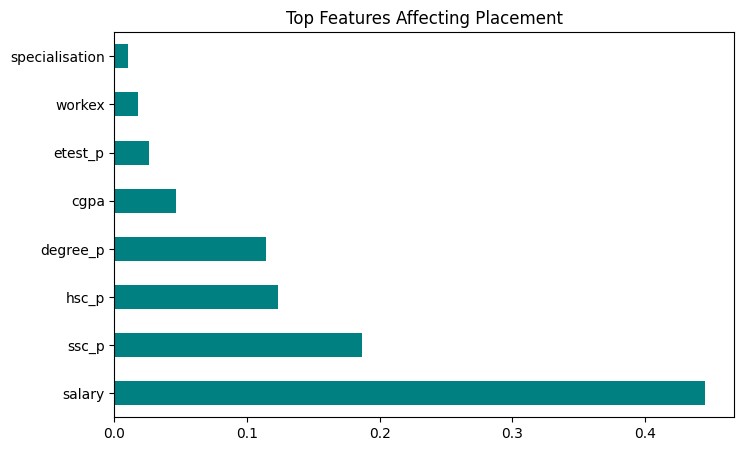

In [11]:
# 9️⃣ Feature Importance Visualization
# ============================================================
plt.figure(figsize=(8,5))
importances = pd.Series(model.feature_importances_, index=X.columns)
importances.nlargest(8).plot(kind='barh', color='teal')
plt.title("Top Features Affecting Placement")
plt.show()

In [12]:
# 🔟 Conclusion
# ============================================================
print("\n🎯 Conclusion:")
print("- Model successfully predicts placement status with high accuracy.")
print("- Higher CGPA, employability test scores, and work experience increase placement chances.")
print("- This model can help students identify key areas to improve before campus placements.")



🎯 Conclusion:
- Model successfully predicts placement status with high accuracy.
- Higher CGPA, employability test scores, and work experience increase placement chances.
- This model can help students identify key areas to improve before campus placements.
